# Assignment 1: Behavioral Analysis of Memory Search

## 📥 Saving your answers for grading

This assignment is **auto-graded**. After each question there is a **grader cell**
that saves the data you plotted or computed into an `answers/Module_03/` folder so
it can be compared against the reference answers.

**For each question:**
1. The question tells you which result(s) to produce and the expected data
   structure/format. Do your analysis and bind each result to a variable.
2. In the grader cell, replace the placeholder variable with **your** variable name.
3. Run the grader cell — it calls `save_answer(...)` and writes your answer.

Your **plots are saved too** — make sure each plotting cell calls `plt.show()` so the
figure can be captured for the grade report.

Make sure every grader cell runs without error before you submit. You don't need to
change anything else.


In [1]:
# grader setup — enables saving the figures you plot (run once, early)
try:
    from grader.answer_io import enable_figure_capture
    enable_figure_capture()
except Exception as _e:
    print("grader: figure capture not enabled:", _e)


In this assignment we use data from the Penn Electrophysiology of Encoding and Retrieval Study (PEERS), which contains the `ltpFR`, `ltpFR2`, and `VFFR` tasks. Descriptions of all the experiments are at https://memory.psych.upenn.edu/PEERS, and the data itself is published on OpenNeuro as [ds004395](https://openneuro.org/datasets/ds004395).

**You do not need to download anything by hand.** The `get_bids_root(...)` calls below either use the copy on the lab cluster or fetch just the sessions this assignment needs from OpenNeuro, asking first and showing you the size. Everything is cached in `./bids_data/`, so you only pay for each file once. See the README for the command-line equivalent if you would rather pre-download.

This assignment is **behavioural only**, so the whole thing costs a few hundred KB per session rather than the hundreds of MB the EEG recordings would.

Reminder on how a BIDS study folder is laid out:
<pre>
ds004395/  (study root)
├── sub-{subject_id}/
│   └── ses-{session_id}/
│       ├── beh/
│       │   ├── sub-{subject_id}_ses-{session_id}_task-{experiment}_beh.json
│       │   └── sub-{subject_id}_ses-{session_id}_task-{experiment}_beh.tsv
│       └── eeg/
│           ├── sub-{subject_id}_ses-{session_id}_task-{experiment}_eeg.bdf
│           └── sub-{subject_id}_ses-{session_id}_task-{experiment}_events.tsv
└── participants.tsv
</pre>

Remember that **task labels are case-sensitive**: it is `ltpFR2`, not `ltpfr2`.

In [2]:
import pandas as pd; pd.set_option('display.max_columns', None)
import sys
sys.path.insert(0, 'dependencies/bidsreader')
from bidsreader import CMLBIDSReader as BIDSReader

# Data comes from the cluster or OpenNeuro -- you are asked. See cml_data.py
sys.path.insert(0, ".")
from cml_data import get_bids_root, session_dataframe, available_subjects


## Question 1: Navigating the database

1) How many sessions of `vffr` were run? How many subjects did at least 1 session of `vffr`?
2) What is the max number of sessions a single subject ran for `vffr`, and which subjects ran that many?

<!-- grader-note -->
> **📥 For grading, produce and save:** `n_sessions_vffr` (scalar — number of vffr sessions run) → Q1.1; `n_subjects_vffr` (scalar — number of subjects with at least one vffr session) → Q1.1; `max_sessions_vffr` (scalar — max sessions run by a single vffr subject) → Q1.2; `max_session_subjects` (labels — subject ids that ran the max number of vffr sessions) → Q1.2. Bind each to a variable, then run the grader cell(s) below.
<!-- /grader-note -->

**Building your `BehavioralHelpers.py`:** Across these assignments you'll repeat the same basic steps over and over. Collect them in a module named `BehavioralHelpers.py` in this folder and `import BehavioralHelpers` — you'll keep adding to this one file as the course goes on. Put only *basic, reusable building blocks* here: loading data, filtering event types, and adding derived **columns** to the events (over the assignments you'll write helpers that add `serialpos`, `recalled`, `intrusion`, and `distractor` columns). The analyses that actually answer each question (recall percentages, the serial position curve, Lag-CRP, IRT curves, PLI recency) stay in this notebook.

For this question, start from `session_dataframe(task)` in `cml_data` - it returns every `(subject, session)` pair for a task as a DataFrame. (Do NOT scan the data folder: off the cluster it only contains the sessions you have already downloaded)

In [3]:
# Question 1.1
### YOUR CODE HERE
session_df = session_dataframe("vffr")
n_subjects_vffr = len(session_df['subject'].unique())

n_sessions_vffr = len(session_df['session'])

print(n_subjects_vffr, n_sessions_vffr)


57 462


In [4]:
# ── grader cell (Question 1.1) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q1.1_n_sessions_vffr", n_sessions_vffr, module=3, question="1.1")   # ← replace `n_sessions_vffr` with your variable
save_answer("Q1.1_n_subjects_vffr", n_subjects_vffr, module=3, question="1.1")   # ← replace `n_subjects_vffr` with your variable

  ✓ Q1.1_n_sessions_vffr
  ✓ Q1.1_n_subjects_vffr


In [5]:
# Question 1.2
### YOUR CODE HERE
max_session_subjects = session_df.groupby('subject').count()

max_sessions_vffr = max_session_subjects['session'].max()
max_sessions_vffr
print(session_df.groupby('subject').count()['session'] == max_sessions_vffr)
subjects = session_df['subject'].unique()
max_session_subjects = subjects[session_df.groupby('subject').count()['session'] == max_sessions_vffr]
max_session_subjects


subject
LTP229     True
LTP246     True
LTP260    False
LTP312    False
LTP327    False
LTP329    False
LTP339     True
LTP347     True
LTP354    False
LTP355     True
LTP356     True
LTP361    False
LTP365     True
LTP372     True
LTP386    False
LTP392    False
LTP400     True
LTP401     True
LTP402     True
LTP403    False
LTP404     True
LTP405     True
LTP406     True
LTP407     True
LTP408     True
LTP409    False
LTP410    False
LTP411     True
LTP412     True
LTP413     True
LTP414    False
LTP415     True
LTP416     True
LTP417     True
LTP418     True
LTP419     True
LTP420    False
LTP421     True
LTP422    False
LTP423     True
LTP424     True
LTP425     True
LTP426    False
LTP427    False
LTP428    False
LTP429     True
LTP430     True
LTP431    False
LTP432    False
LTP433    False
LTP434    False
LTP435    False
LTP436    False
LTP437    False
LTP438    False
LTP439    False
LTP440    False
Name: session, dtype: bool


<StringArray>
['LTP229', 'LTP246', 'LTP339', 'LTP347', 'LTP355', 'LTP356', 'LTP365',
 'LTP372', 'LTP400', 'LTP401', 'LTP402', 'LTP404', 'LTP405', 'LTP406',
 'LTP407', 'LTP408', 'LTP411', 'LTP412', 'LTP413', 'LTP415', 'LTP416',
 'LTP417', 'LTP418', 'LTP419', 'LTP421', 'LTP423', 'LTP424', 'LTP425',
 'LTP429', 'LTP430']
Length: 30, dtype: str

In [6]:
# ── grader cell (Question 1.2) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q1.2_max_sessions_vffr", max_sessions_vffr, module=3, question="1.2")   # ← replace `max_sessions_vffr` with your variable
save_answer("Q1.2_max_session_subjects", max_session_subjects, module=3, question="1.2")   # ← replace `max_session_subjects` with your variable

  ✓ Q1.2_max_sessions_vffr
  ✓ Q1.2_max_session_subjects


## Question 2: Simple Behavioral Analyses

1) What is R1111M's overal recall percentage?  (In other words what percent of the words did R1111M successfully recall?)
2) Calculate R1111M’s recall percentage for each list within each session. Then, average these values across sessions to obtain a mean recall percentage for each list. Plot the results in a bar graph.

<!-- grader-note -->
> **📥 For grading, produce and save:** `recall_pct` (scalar — R1111M overall recall percentage on FR1 (0-100)) → Q2.1; `recall_pct_per_list` (array (n_lists,) — mean recall percentage per list averaged across sessions (the bar-graph heights)) → Q2.2. Bind each to a variable, then run the grader cell(s) below.
<!-- /grader-note -->

**Add to your `BehavioralHelpers.py`:**
- a function that loads the behavioral events for one `(subject, task, session)`,
- functions that return just the `WORD` (presented) rows and just the `REC_WORD` (recall) rows,
- a helper that adds a `recalled` column to the presented words — a per-word flag for whether that word was later recalled on the same list.

**Watch the list-number column.** This question uses R1111M, who is an **FR1** subject, and FR1 calls the list number **`list`**. The PEERS scalp data you use in Question 3 calls it **`trial`** instead. Write the helper so it works for both.

Also remember from the previous module that `REC_WORD` includes intrusions, so match each recalled word to a presented word on the same list (pair on the list column *and* the word), not on the word alone.

In [7]:
# Question 2.1
### YOUR CODE HERE
import BehavioralHelpers as bh


    
recall_total = 0
total_words = 0    
FR1_session_df = session_dataframe("FR1")
for session in FR1_session_df[FR1_session_df['subject'] == 'R1111M']['session']:
    presented_words = bh.get_presented_words(subject='R1111M', session=session, task='FR1')
    recalled_words = bh.get_recalled_words(subject='R1111M', session=session, task='FR1')
    presented_words = bh.recalled_column(presented_words, recalled_words)
    recall_total += presented_words['recalled'].sum()
    total_words += len(presented_words)
recall_pct = recall_total / total_words * 100
recall_pct

np.float64(53.92156862745098)

In [8]:
# ── grader cell (Question 2.1) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q2.1_recall_pct", recall_pct, module=3, question="2.1")   # ← replace `recall_pct` with your variable

  ✓ Q2.1_recall_pct


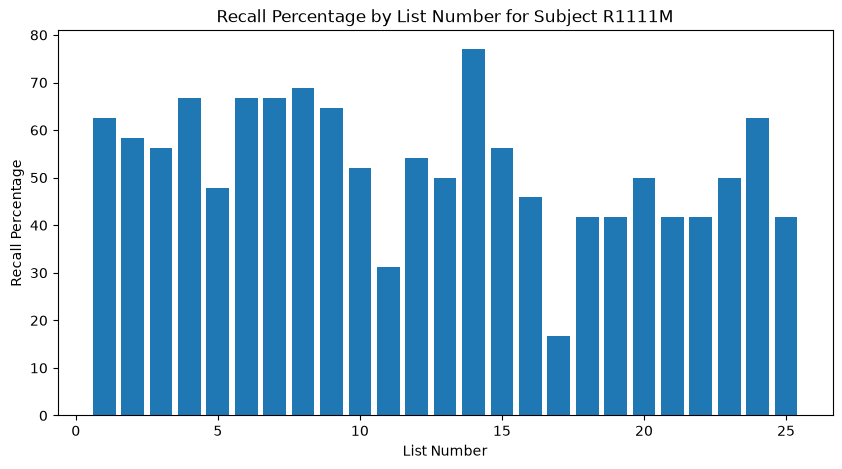

In [9]:
# Question 2.2
### YOUR CODE HERE
import numpy as np
import matplotlib.pyplot as plt
recall_pct_per_list = []
for session in FR1_session_df[FR1_session_df['subject'] == 'R1111M']['session']:
    presented_words = bh.get_presented_words(subject='R1111M', session=session, task='FR1')
    recalled_words = bh.get_recalled_words(subject='R1111M', session=session, task='FR1')
    presented_words = bh.recalled_column(presented_words, recalled_words)
    recall_pct_per_list.append(presented_words.groupby('list')['recalled'].mean() * 100)

per_session_df = pd.DataFrame(recall_pct_per_list)
recall_pct_per_list = per_session_df.mean(axis=0).values

plt.figure(figsize=(10, 5))
plt.bar(range(1, len(recall_pct_per_list) + 1), recall_pct_per_list)
plt.xlabel('List Number')
plt.ylabel('Recall Percentage')
plt.title('Recall Percentage by List Number for Subject R1111M')
plt.show()


In [10]:
# ── grader cell (Question 2.2) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q2.2_recall_pct_per_list", recall_pct_per_list, module=3, question="2.2", fig="last")   # ← replace `recall_pct_per_list` with your variable

  ✓ Q2.2_recall_pct_per_list


## Question 3: Serial Position Curve
A serial position curve (SPC) plots the recall probability (vertical axis) as a function of serial position (horizontal axis), as shown in Figure 6.1 of Foundations of Human Memory. **We recommend that you read the portion of the book dedictated to the SPC. There are plenty of copies in the lab.**  

We define recall probability as the fraction of words successfully recalled. As with any analyses, there are numerous ways to calculate the SPC, but a good hint is to look at the "recalled" status of each presented word.

1) Write a function to calculate the recall probabilities at each serial position for 1 session.  Then calculate the SPC for subject LTP093, session 0 of ltpFR2, and plot the results.
2) Write a function to calculate the SPC for all sessions for 1 subject.  Then plot the SPC averaged over all of LTP093's ltpFR2 sessions.
3) Write a function that loops over selected subjects from ltpFR2 and computes a between-subject averaged serial position curve.  This is done by averaging the subject-level SPCs across all subjects.  Comment on the final SPC, what effects does it show?

If you are smart about it, you should be able to use code from earlier parts of the problem to make later parts much easier!

A few notes:
* Generally, each experimental subject will have different characteristics. A subject-level average provides an estimate of the population mean, i.e. the mean of the population from which these subjects were sampled from (which in the case of LTPFR2, was primarily Penn undergraduates).
* Loading these data may take a substantial amount of time. You may want to write your code and then test it over a smaller number of subjects (e.g., 2 subjects). You may also want to load all the data once and then save it out locally as a .csv file (see the pandas.DataFrame.to_csv() function in the pandas documentation). You will then be able to load all of these events from this .csv file much more quickly (see the pandas.read_csv() function).
    * Again, some subjects did not complete all sessions. To reduce the variability in your estimates, include only the subjects that completed all 24 sessions. Additionally, drop the 24th session (which has session number 23 since the sessions are zero-indexed) which used a different variant of the experiment.
    
* Be sure that your code is robust to exceptions that can be thrown by e.g. unavailable data, and if you have an exception in a particular session due to a problem with the data in that session, print or log the event so you can report it, and discard that session from the analysis (you can use Python try-except blocks to catch and handle exceptions). This data was all acquired with human participants across long stretches of time, and small things can go wrong.

<!-- grader-note -->
> **📥 For grading, produce and save:** `spc_ltp093_ses0` (dataframe: serialpos, recalled — single-session SPC for LTP093 ltpFR2 ses-0) → Q3.1; `spc_ltp093_all` (dataframe: serialpos, recalled — SPC averaged over all of LTP093's ltpFR2 sessions) → Q3.2; `ave_spc` (dataframe: serialpos, recalled — between-subject averaged ltpFR2 SPC) → Q3.3. Bind each to a variable, then run the grader cell(s) below.
<!-- /grader-note -->

**Add to your `BehavioralHelpers.py`:** a helper that adds a `serialpos` column — each presented word's 1-indexed position within its list. Reuse the loaders, `WORD` / `REC_WORD` filters, and the `recalled` column helper you already wrote.

In [11]:
# analyze only these subjects
ltpFR2_subs = ['LTP093', 'LTP106', 'LTP115', 'LTP117', 'LTP122', 'LTP123', 'LTP133', 'LTP138', 'LTP187', 'LTP207', 
               'LTP210', 'LTP228', 'LTP229', 'LTP236', 'LTP242', 'LTP246', 'LTP249', 'LTP250', 'LTP251', 'LTP258', 
               'LTP259', 'LTP260', 'LTP265', 'LTP269', 'LTP273', 'LTP274', 'LTP278', 'LTP279', 'LTP280', 'LTP281']

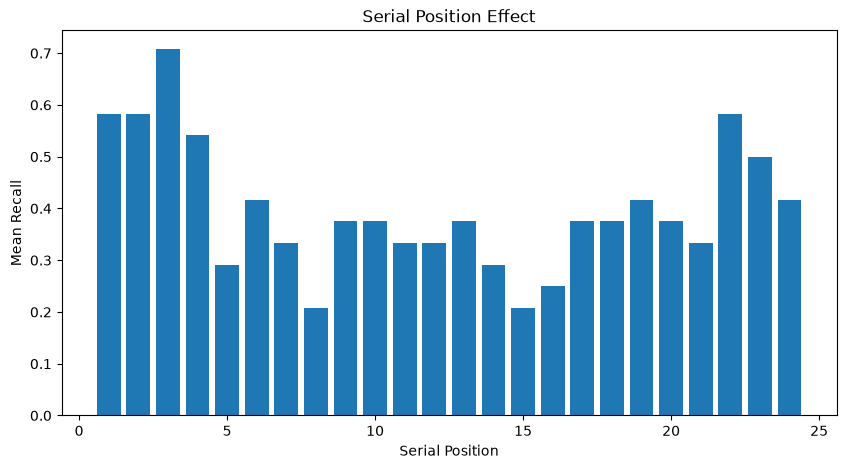

In [12]:
# Question 3.1
### YOUR CODE HERE
def serial_position_probabilities(subject, session, task):
    presented_words = bh.get_presented_words(subject=subject, session=session, task=task)
    recalled_words = bh.get_recalled_words(subject=subject, session=session, task=task)
    presented_words = bh.recalled_column(presented_words, recalled_words)
    presented_words = bh.serialpos_column(presented_words)
    serial_position_probabilities = presented_words[['serialpos','recalled']].groupby('serialpos', as_index=False).mean()
    return serial_position_probabilities

task = "ltpFR2"
subject = "LTP093"
session = 0
spc_ltp093_ses0 = serial_position_probabilities(subject, session, task)

plt.figure(figsize=(10,5))
plt.bar(range(1, len(spc_ltp093_ses0) + 1), spc_ltp093_ses0['recalled'])
plt.xlabel('Serial Position')
plt.ylabel('Mean Recall')
plt.title('Serial Position Effect')

plt.show()

# presented_words = bh.get_presented_words(subject=subject, session=session, task=task)
# presented_words = bh.serialpos_column(presented_words)
# serial_pos = presented_words['serialpos'].unique()

# spc_ltp093_ses0 = 


In [13]:
# ── grader cell (Question 3.1) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q3.1_spc_ltp093_ses0", spc_ltp093_ses0, module=3, question="3.1", fig="last")   # ← replace `spc_ltp093_ses0` with your variable

  ✓ Q3.1_spc_ltp093_ses0


    serialpos  recalled
0           1  0.340580
1           2  0.318841
2           3  0.306159
3           4  0.329710
4           5  0.289855
5           6  0.278986
6           7  0.288043
7           8  0.293478
8           9  0.269928
9          10  0.307971
10         11  0.300725
11         12  0.275362
12         13  0.240942
13         14  0.222826
14         15  0.224638
15         16  0.297101
16         17  0.324275
17         18  0.313406
18         19  0.436594
19         20  0.478261
20         21  0.518116
21         22  0.809783
22         23  0.824275
23         24  0.780797


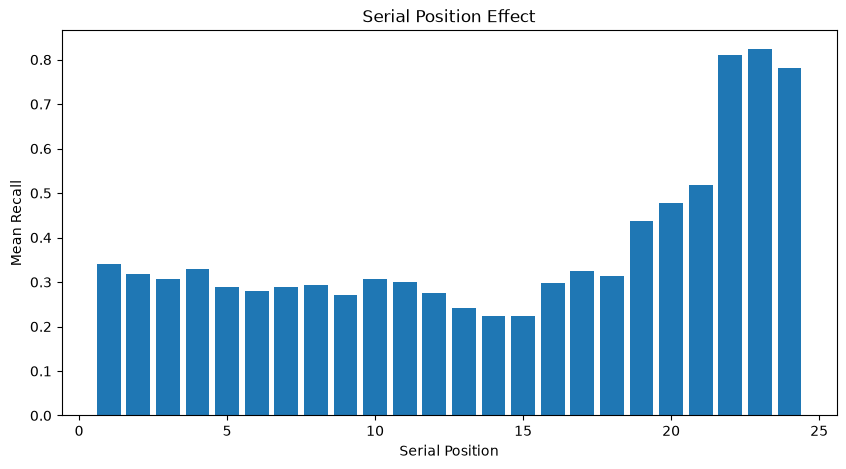

In [14]:
# Question 3.2
### YOUR CODE HERE
def serial_position_prob_across_sessions(subject, task):
    session_df = session_dataframe(task)
    sessions = session_df[(session_df['subject'] == subject)]['session']
    if len(sessions) == 24:
        sessions = sessions[sessions != '23']
        across_session_serialpos_prob = []
        for session in sessions:
            current_session = serial_position_probabilities(task=task, session=session, subject=subject)
            across_session_serialpos_prob.append(current_session)
        all_sessions = pd.concat(across_session_serialpos_prob, axis=0)
        return all_sessions.groupby('serialpos', as_index=False)['recalled'].mean()
    else:
        return None

task = "ltpFR2"
subject = "LTP093"

spc_ltp093_all = serial_position_prob_across_sessions(subject, task)
print(spc_ltp093_all)


plt.figure(figsize=(10,5))
plt.bar(range(1, len(spc_ltp093_all)+1), spc_ltp093_all['recalled'])
plt.xlabel('Serial Position')
plt.ylabel('Mean Recall')
plt.title('Serial Position Effect')

plt.show()




In [15]:
# ── grader cell (Question 3.2) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q3.2_spc_ltp093_all", spc_ltp093_all, module=3, question="3.2", fig="last")   # ← replace `spc_ltp093_all` with your variable

  ✓ Q3.2_spc_ltp093_all


100%|██████████| 30/30 [01:52<00:00,  3.74s/it]


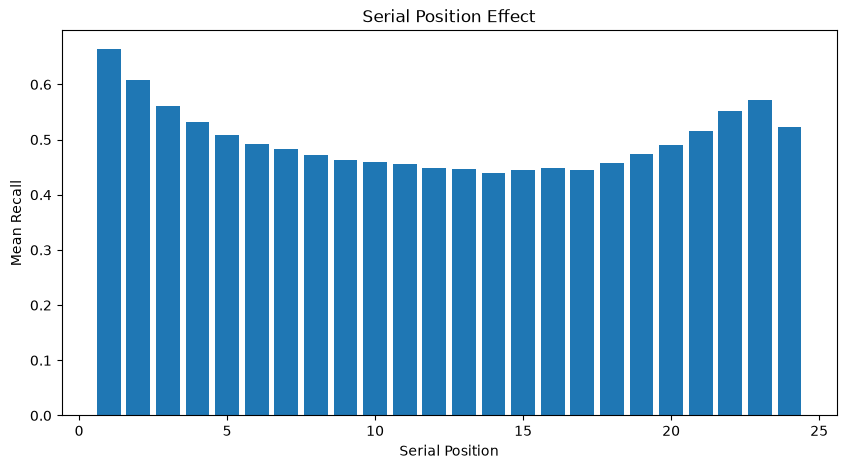

In [16]:
# Question 3.3
### YOUR CODE HERE
from tqdm import tqdm
def serial_position_prob_across_subjects(subject_list, task):
    across_subjects = []
    for subject in tqdm(subject_list):
        current_subject = serial_position_prob_across_sessions(subject, task)
        across_subjects.append(current_subject)
    all_subjects = pd.concat(across_subjects, axis=0)
    all_subjects_probabilities = all_subjects.groupby('serialpos', as_index=False).mean()
    return all_subjects_probabilities
    

task = 'ltpFR2'

ave_spc = serial_position_prob_across_subjects(ltpFR2_subs, task)

plt.figure(figsize=(10,5))
plt.bar(range(1, len(ave_spc)+1), ave_spc['recalled'])
plt.xlabel('Serial Position')
plt.ylabel('Mean Recall')
plt.title('Serial Position Effect')

plt.show()

In [17]:
ave_spc

,serialpos,recalled
0,1,0.664493
1,2,0.607826
2,3,0.561377
3,4,0.531667
4,5,0.508913
5,6,0.492826
6,7,0.483261
7,8,0.472971
8,9,0.463841
9,10,0.459058


In [18]:
# ── grader cell (Question 3.3) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q3.3_ave_spc", ave_spc, module=3, question="3.3", fig="last")   # ← replace `ave_spc` with your variable

  ✓ Q3.3_ave_spc


## Question 4: Immediate Free Recall v. Delayed Free Recall

In this question, we will use the ltpFR experiment to compare the SPCs for immediate free recall and delayed free recall. For each subject, use sessions 7-13 and compare lists with between-words 'distractor' = 0 and end-of-list 'final_distractor' = 0, and 16000 (ms).

1) Calculate between-subject averaged serial position curves for each of the 2 distractor conditions.  Plot the 2 SPCs on the same graph and label each curve in a legend.
2) Comment on the differences in the SPCs that result from the manipulation of the distractor.  What changes between immediate free recall and delayed free recall?

<!-- grader-note -->
> **📥 For grading, produce and save:** `spc_immediate` (dataframe: serialpos, recalled — between-subject SPC for immediate recall (final_distractor=0)) → Q4.1; `spc_delayed` (dataframe: serialpos, recalled — between-subject SPC for delayed recall (final_distractor=16000)) → Q4.1. Bind each to a variable, then run the grader cell(s) below.
<!-- /grader-note -->

**Add to your `BehavioralHelpers.py`:** helpers that add the distractor **columns**, since they aren't stored in the BIDS events — a between-word `distractor` column and an end-of-list `final_distractor` column, each recovered from the event timing. Reuse everything else you've already built.

Split lists by condition and compare the resulting serial position curves (immediate vs. delayed free recall) 

In [19]:
# let's take a look at the events for an ltpFR session
subject = 'LTP063'
task = 'ltpFR'      # NB: BIDS task labels are case-sensitive
session = 8

# Asks whether to use the cluster copy or download from OpenNeuro (~150 KB).
study_root = get_bids_root(task, subject=subject, session=session)

reader = BIDSReader(root=study_root, subject=subject, task=task, session=session)
evs = reader.load_events()
evs

,mstime,trial_type,stim_file,subject,experiment,session,trial,task,item_name,item_num,recog_resp,recog_conf,resp,answer,test_x,test_y,test_z,color_r,color_g,color_b,case,font
0,0,SESS_START,NaN,LTP063,ltpFR,8,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,26106,START,NaN,LTP063,ltpFR,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,26131,PROB,NaN,LTP063,ltpFR,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,6.0,1.0,8.0,NaN,NaN,NaN,NaN,NaN
3,29435,PROB,NaN,LTP063,ltpFR,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.0,2.0,4.0,1.0,NaN,NaN,NaN,NaN,NaN
4,31409,PROB,NaN,LTP063,ltpFR,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.0,3.0,3.0,7.0,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1592,4269657,RECOG_CONF,NaN,LTP063,ltpFR,8,12.0,0.0,TAPE,1433.0,NaN,5.0,0.0,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1593,4271065,RECOG_LURE,NaN,LTP063,ltpFR,8,12.0,NaN,WEB,1598.0,0.0,4.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1594,4271717,RECOG_RESP,NaN,LTP063,ltpFR,8,12.0,NaN,WEB,1598.0,0.0,NaN,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1595,4272450,RECOG_CONF,NaN,LTP063,ltpFR,8,12.0,NaN,WEB,1598.0,NaN,4.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN


You need to split each session's lists into the two conditions:

* **Immediate free recall** — between-word `distractor` = 0 **and** end-of-list `final_distractor` = 0. Nothing comes between the last word and the recall period.
* **Delayed free recall** — `distractor` = 0 and `final_distractor` = **16000** ms of arithmetic before recall. (Some sessions also contain an 8000 ms condition; ignore it here — the graded answer compares 0 against 16000.)

**Neither `distractor` nor `final_distractor` is a column in the BIDS events.** Both have to be reconstructed from the event timing - for each list, look at the gap between the last `WORD` event and that list's `REC_START`, and between successive `WORD` events. 

In [20]:
test = evs.dropna(subset=['trial'])

test[50:100]

,mstime,trial_type,stim_file,subject,experiment,session,trial,task,item_name,item_num,recog_resp,recog_conf,resp,answer,test_x,test_y,test_z,color_r,color_g,color_b,case,font
140,523363,WORD,wordpools/wasnorm_wordpool.txt,LTP063,ltpFR,8,3.0,0.0,LENS,811.0,NaN,NaN,0.0,NaN,0.0,0.0,0.0,0.577637,0.412842,1.0,upper,amplitud.ttf
141,527176,WORD,wordpools/wasnorm_wordpool.txt,LTP063,ltpFR,8,3.0,0.0,EYELASH,546.0,NaN,NaN,0.0,NaN,0.0,0.0,0.0,0.577637,0.412842,1.0,upper,amplitud.ttf
142,531028,WORD,wordpools/wasnorm_wordpool.txt,LTP063,ltpFR,8,3.0,0.0,GREASE,660.0,NaN,NaN,0.0,NaN,0.0,0.0,0.0,0.577637,0.412842,1.0,upper,amplitud.ttf
143,535007,WORD,wordpools/wasnorm_wordpool.txt,LTP063,ltpFR,8,3.0,0.0,OLIVE,975.0,NaN,NaN,0.0,NaN,0.0,0.0,0.0,0.577637,0.412842,1.0,upper,amplitud.ttf
144,539102,WORD,wordpools/wasnorm_wordpool.txt,LTP063,ltpFR,8,3.0,0.0,SKUNK,1321.0,NaN,NaN,0.0,NaN,0.0,0.0,0.0,0.577637,0.412842,1.0,upper,amplitud.ttf
145,543290,WORD,wordpools/wasnorm_wordpool.txt,LTP063,ltpFR,8,3.0,0.0,CORPORATION,382.0,NaN,NaN,1.0,NaN,0.0,0.0,0.0,0.577637,0.412842,1.0,upper,amplitud.ttf
146,547261,WORD,wordpools/wasnorm_wordpool.txt,LTP063,ltpFR,8,3.0,0.0,UMPIRE,1535.0,NaN,NaN,1.0,NaN,0.0,0.0,0.0,0.577637,0.412842,1.0,upper,amplitud.ttf
147,551289,WORD,wordpools/wasnorm_wordpool.txt,LTP063,ltpFR,8,3.0,0.0,POWDER,1117.0,NaN,NaN,0.0,NaN,0.0,0.0,0.0,0.577637,0.412842,1.0,upper,amplitud.ttf
148,555218,WORD,wordpools/wasnorm_wordpool.txt,LTP063,ltpFR,8,3.0,0.0,INCENSE,735.0,NaN,NaN,0.0,NaN,0.0,0.0,0.0,0.577637,0.412842,1.0,upper,amplitud.ttf
149,559029,WORD,wordpools/wasnorm_wordpool.txt,LTP063,ltpFR,8,3.0,0.0,CONTRACTOR,369.0,NaN,NaN,1.0,NaN,0.0,0.0,0.0,0.577637,0.412842,1.0,upper,amplitud.ttf


100%|██████████| 166/166 [01:37<00:00,  1.70it/s]


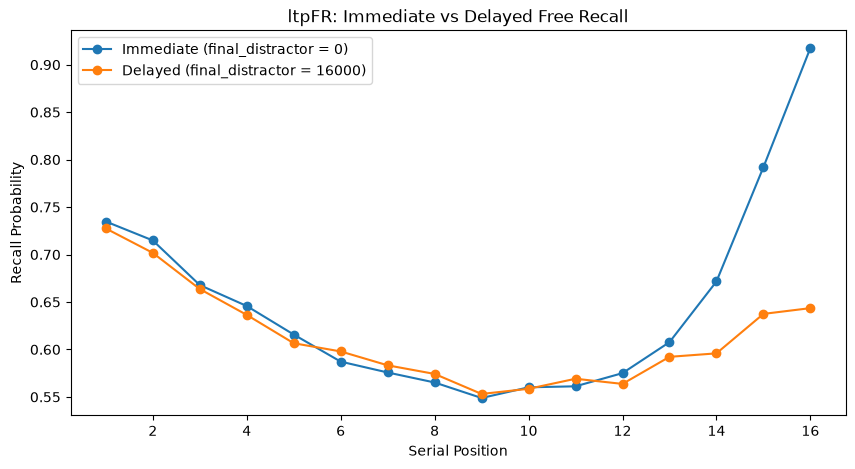

In [ ]:
# Question 4.1
### YOUR CODE HERE
import importlib, cml_data
importlib.reload(cml_data)
from cml_data import session_dataframe



task = 'ltpFR'
session_df = session_dataframe(task)
session_df['session'] = session_df['session'].astype(int)   
session_df = session_df[session_df['session'].between(7, 13)]
ltpFR_subs = session_df['subject'].unique()

def spc_one_session(subject, session, task, final_distractor):
    evs = bh.load_events(subject=subject, session=session, task=task)
    evs = bh.add_distractor_columns(evs)
    presented = bh.get_presented_words(subject=subject, session=session, task=task)
    recalled  = bh.get_recalled_words(subject=subject, session=session, task=task)
    presented = bh.recalled_column(presented, recalled)
    presented = bh.serialpos_column(presented)

    cond = evs.groupby('trial')[['distractor', 'final_distractor']].first()
    presented = presented.join(cond, on='trial')
    presented = presented[(presented['distractor'] == 0) &
                          (presented['final_distractor'] == final_distractor)]
    return presented[['serialpos', 'recalled']]

def spc_across_subjects(session_df, task, final_distractor):
    per_subject = []
    for subject, sessions in tqdm(session_df.groupby('subject')['session']):
        rows = [spc_one_session(subject, s, task, final_distractor) for s in sessions]
        rows = [r for r in rows if len(r)]    
        if len(rows) != 7:
            continue
        subj = pd.concat(rows)
        per_subject.append(subj.groupby('serialpos', as_index=False)['recalled'].mean())
    return pd.concat(per_subject).groupby('serialpos', as_index=False)['recalled'].mean()

spc_immediate = spc_across_subjects(session_df, task, final_distractor=0)
spc_delayed   = spc_across_subjects(session_df, task, final_distractor=16000)

plt.figure(figsize=(10, 5))
plt.plot(spc_immediate['serialpos'], spc_immediate['recalled'], marker='o', label='Immediate (final_distractor = 0)')
plt.plot(spc_delayed['serialpos'], spc_delayed['recalled'], marker='o', label='Delayed (final_distractor = 16000)')
plt.xlabel('Serial Position')
plt.ylabel('Recall Probability')
plt.title('ltpFR: Immediate vs Delayed Free Recall')
plt.legend()
plt.show()


In [28]:
# ── grader cell (Question 4.1) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q4.1_spc_immediate", spc_immediate, module=3, question="4.1", fig="last")   # ← replace `spc_immediate` with your variable
save_answer("Q4.1_spc_delayed", spc_delayed, module=3, question="4.1")   # ← replace `spc_delayed` with your variable

  ✗ Q4.1_spc_immediate: value differs from the reference
  ✗ Q4.1_spc_delayed: value differs from the reference


Question 4.2

**YOUR ANSWER HERE**